# Understanding Another Mind

*The Mathematics of Machine Intelligence · Chapter 22*

Read goals and beliefs from steps, and see why one correct answer rarely settles which reading is right.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the observed agent could see or know, what options it had, and what a choice rule with some noise would predict. Then score the candidate goals with Bayes' rule, using the chance of each step under each goal. Before reading a choice as a preference, compare the readings that fit with and without missing knowledge. When a test result is offered as proof of understanding, compare how likely a pass is under each rival explanation, and say that a good fit to behavior does not establish a private motive or belief.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 22, Understanding Another Mind: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def goal_posterior(prior_a, step_prob_a, step_prob_b, steps):
    """Chance of goal A after `steps` identical steps, each with the given chance under each goal."""
    if not 0 < prior_a < 1:
        raise ValueError('The prior must be strictly between 0 and 1.')
    score_a = prior_a * step_prob_a ** steps
    score_b = (1 - prior_a) * step_prob_b ** steps
    if score_a + score_b <= 0:
        raise ValueError('At least one goal must make the walk possible.')
    return score_a / (score_a + score_b)

def goal_picture(step_prob=0.8, steps=1, prior_a=0.5):
    q = 1 - step_prob
    path = [goal_posterior(prior_a, step_prob, q, t) for t in range(steps + 1)]
    final = path[-1]
    score_a, score_b = (prior_a * step_prob ** steps, (1 - prior_a) * q ** steps)
    fig, ax = panels()
    ax[0].plot(range(steps + 1), path, color=NAVY, linewidth=2.5, marker='o', markersize=6, label='goal A')
    ax[0].plot(range(steps + 1), [1 - x for x in path], color=TERRA, linewidth=2, linestyle='dashed', marker='s', markersize=5, label='goal B')
    for t, v in enumerate(path):
        tag(ax[0], t, v + 0.05 if v < 0.9 else v - 0.09, sig(v), color=NAVY)
    ax[0].set(xlabel='steps seen', ylabel='chance of each goal', title='Belief after each step', ylim=(-0.02, 1.08), xticks=range(steps + 1))
    ax[0].legend(fontsize=9, loc='center right')
    grid = np.linspace(0.05, 0.95, 91)
    for t, style, colour in [(1, 'dotted', GREY), (2, 'dashed', GOLD), (3, 'solid', TEAL)]:
        chosen = t == steps
        ax[1].plot(grid, [goal_posterior(prior_a, p, 1 - p, t) for p in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'{t} step' + ('s' if t > 1 else ''))
    ax[1].axhline(prior_a, color=GREY, linestyle='dotted', linewidth=1)
    tag(ax[1], 0.78, prior_a + 0.045, 'prior', color=GREY, fontsize=9)
    ring(ax[1], step_prob, final)
    ax[1].set(xlabel='chance of the step under goal A (B gets the rest)', ylabel='chance of goal A afterward', title='Steps that fit A pile up', ylim=(-0.02, 1.02))
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Goal A before any step': sig(prior_a), 'Goal A after the steps': sig(final), 'Score of A (unscaled)': sig(score_a), 'Score of B (unscaled)': sig(score_b)}
    summary = f"Starting at {sig(prior_a)} for goal A, {steps} step{('s' if steps > 1 else '')} with chance {sig(step_prob)} under A and {sig(q)} under B give A a chance of {sig(final)}. Each step multiplies A's score by {sig(step_prob)} and B's by {sig(q)}, so the pull compounds."
    calc = f'Score of A = {sig(prior_a)} x {sig(step_prob)}^{steps} = {sig(score_a)}. Score of B = {sig(1 - prior_a)} x {sig(q)}^{steps} = {sig(score_b)}. Chance of A = {sig(score_a)} / ({sig(score_a)} + {sig(score_b)}) = {sig(final)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
MINUTES = np.array([18.0, 24.0, 30.0])
TOLLS = np.array([3.0, 0.0, 0.0])
TIME_WEIGHT = 0.2
ROUTES = ['Express', 'Arterial', 'Back roads']

def softmax_cost(costs, carefulness=1.0):
    """Chance of each option when value is minus cost: exp(-beta c) / sum exp(-beta c')."""
    costs = np.asarray(costs, dtype=float)
    z = -carefulness * costs
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

def route_costs(toll_weight, time_weight=TIME_WEIGHT):
    return time_weight * MINUTES + toll_weight * TOLLS

def fleet_shares(unaware, toll_weight):
    """Trip shares over (Express, Arterial, Back roads) when a share `unaware` never heard of Express."""
    costs = route_costs(toll_weight)
    knowing = softmax_cost(costs)
    ignorant = np.concatenate([[0.0], softmax_cost(costs[1:])])
    return (1 - unaware) * knowing + unaware * ignorant

def analyst_fit(shares):
    """Weights that make a full-knowledge softmax (carefulness 1) match the shares, from two log-odds."""
    s_e, s_a, s_b = shares
    if min(s_e, s_a, s_b) <= 0:
        return None
    time_w = math.log(s_a / s_b) / (MINUTES[2] - MINUTES[1])
    toll_w = ((MINUTES[1] - MINUTES[0]) * time_w - math.log(s_e / s_a)) / TOLLS[0]
    return (time_w, toll_w)

def fleet_picture(unaware=0.4, toll_weight=0.4):
    costs = route_costs(toll_weight)
    shares = fleet_shares(unaware, toll_weight)
    full = softmax_cost(costs)
    fit = analyst_fit(shares)
    fig, ax = panels()
    x = np.arange(3)
    ax[0].bar(x, 100 * shares, color=[TERRA, TEAL, GREY], width=0.6, label='what the fleet does')
    ax[0].plot(x, 100 * full, linestyle='none', marker='D', markersize=8, markerfacecolor='white', markeredgecolor=NAVY, markeredgewidth=2, label='if everyone knew all roads')
    for xi, s in zip(x, shares):
        tag(ax[0], xi, 100 * s + 1.5, f'{100 * s:.0f}', va='bottom')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels([f'{r}\ncost {sig(c)}' for r, c in zip(ROUTES, costs)], fontsize=9)
    ax[0].set(ylabel='trips out of 100', title='Who takes which road', ylim=(0, max(100 * max(shares.max(), full.max()) * 1.35, 10)))
    ax[0].legend(fontsize=8.5, loc='upper right')
    grid = np.linspace(0, 0.8, 81)
    for tw, style, colour in [(0.2, 'dotted', GREY), (0.4, 'solid', TEAL), (0.8, 'dashed', TERRA)]:
        chosen = tw == toll_weight
        curve = [analyst_fit(fleet_shares(u, tw))[1] for u in grid]
        ax[1].plot(grid, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'true toll weight {tw:g}')
        ax[1].plot([0], [tw], marker='v', markersize=7, color=colour)
    if fit is not None:
        ring(ax[1], unaware, fit[1])
    ax[1].set(xlabel='share who never heard of Express', ylabel='toll weight the analyst reads off', title='Ignorance looks like dislike', ylim=(0, 2.2))
    ax[1].legend(fontsize=8.5, loc='upper left')
    if fit is None:
        fitted_toll, hour = ('undefined (no trips on Express)', 'undefined (no trips on Express)')
        fit_text = 'Nobody takes Express, so its log-odds against Arterial is undefined and no weight can be fitted.'
    else:
        fitted_toll = sig(fit[1])
        hour = sig(60 * fit[0] / fit[1])
        fit_text = f"The analyst reads a toll weight of {sig(fit[1])} per dollar and an hour worth {hour} dollars; the drivers' true toll weight is {sig(toll_weight)} and the true hour is worth {sig(60 * TIME_WEIGHT / toll_weight)} dollars."
    metrics = {'Express trips per 100': f'{100 * shares[0]:.1f}', 'Toll weight the analyst reads': fitted_toll, 'True toll weight': sig(toll_weight), 'Hour of time, as the analyst values it ($)': hour}
    summary = f'With {100 * unaware:.0f} percent of drivers unaware of Express, it draws {100 * shares[0]:.1f} trips per 100 against {100 * full[0]:.1f} if everyone knew it. ' + fit_text
    calc = f'Costs = 0.20 x minutes + {sig(toll_weight)} x toll: Express {sig(costs[0])}, Arterial {sig(costs[1])}, Back roads {sig(costs[2])}. Chance of a route = exp(-cost) / sum. Fleet share of Express = (1 - {sig(unaware)}) x {sig(full[0])} = {sig(shares[0])}. Analyst: time weight = ln(share Arterial / share Back roads) / 6; toll weight = (6 x time weight - ln(share Express / share Arterial)) / 3.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def binomial_pmf(n, p):
    return np.array([math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(n + 1)])

def binomial_tail(n, k, p):
    """Chance of k or more right out of n if every trial independently has chance p."""
    return float(sum((math.comb(n, j) * p ** j * (1 - p) ** (n - j) for j in range(k, n + 1))))
TRIALS = 24

def sarah_picture(correct=21, chance=0.5):
    pmf = binomial_pmf(TRIALS, chance)
    tail = binomial_tail(TRIALS, correct, chance)
    fig, ax = panels()
    ks = np.arange(TRIALS + 1)
    ax[0].bar(ks, pmf, color=[NAVY if k >= correct else GREY for k in ks], width=0.8)
    ax[0].axvline(correct, color=TERRA, linewidth=1.5, linestyle='dashed')
    ax[0].set(xlabel='trials right out of 24', ylabel='chance if every pick has the set chance', title=f'Chance of {correct} or more: {tail:.3g}')
    if pmf[correct:].max() < 0.05 * pmf.max():
        tag(ax[0], 0.97, 0.55, f'navy bars\n({correct} or more)\ntoo small to see', transform=ax[0].transAxes, ha='right', va='top', fontsize=9, color=NAVY)
    grid = np.arange(12, 25)
    for p, style, colour in [(0.5, 'solid', TEAL), (0.6, 'dashed', GOLD), (0.75, 'dotted', TERRA)]:
        chosen = p == chance
        ax[1].plot(grid, [binomial_tail(TRIALS, int(k), p) for k in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'chance {p:g} per trial')
    ring(ax[1], correct, max(tail, 1e-08))
    ax[1].set_yscale('log')
    ax[1].set(xlabel='number right', ylabel='chance of that many or more', title='How often chance gets that many', ylim=(1e-08, 2))
    ax[1].legend(fontsize=9, loc='lower left')
    metrics = {'Expected right by chance': sig(TRIALS * chance), 'Chance of this many or more': f'{tail:.3g}', 'Rate right': sig(correct / TRIALS), 'Rate expected': sig(chance)}
    if tail < 0.01:
        verdict = 'That is rare, so chance at that level fits poorly; it does not say which reading of the task explains the choices.'
    elif tail < 0.1:
        verdict = 'That is uncommon, a weak case against chance at that level, and it does not say which reading explains the choices.'
    else:
        verdict = 'That is not unusual, so this count does not argue against chance at that level.'
    summary = f'If each of 24 picks had a {sig(chance)} chance of being right, {correct} or more right would have chance {tail:.3g}. ' + verdict
    calc = f'Chance of {correct} or more = sum over j from {correct} to 24 of C(24, j) x {sig(chance)}^j x {sig(1 - chance)}^(24 - j) = {tail:.3g}. Expected right = 24 x {sig(chance)} = {sig(TRIALS * chance)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TRACKER_PASS = 0.95

def pass_posterior(prior, matcher_pass, tracker_pass=TRACKER_PASS):
    """Chance of 'tracker' after one pass, given each type's chance of passing the story."""
    denom = prior * tracker_pass + (1 - prior) * matcher_pass
    if denom <= 0:
        raise ValueError('A pass must be possible under at least one type.')
    return prior * tracker_pass / denom

def pass_picture(matcher_pass=0.9, prior=0.5):
    post = pass_posterior(prior, matcher_pass)
    ratio = TRACKER_PASS / matcher_pass
    fig, ax = panels()
    bars = ax[0].bar(['before the pass', 'after the pass'], [prior, post], color=[GREY, NAVY], width=0.5)
    for b, v in zip(bars, [prior, post]):
        tag(ax[0], b.get_x() + b.get_width() / 2, v + 0.03, sig(v), va='bottom')
    ax[0].axhline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    ax[0].set(ylabel='chance the test-taker tracks beliefs', title='One pass moves belief this far', ylim=(0, 1.15))
    grid = np.linspace(0.05, 0.95, 91)
    for pr, style, colour in [(0.1, 'dotted', GREY), (0.5, 'solid', TEAL), (0.9, 'dashed', TERRA)]:
        chosen = pr == prior
        ax[1].plot(grid, [pass_posterior(pr, m) for m in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'prior {pr:g}')
    ring(ax[1], matcher_pass, post)
    ax[1].set(xlabel="pattern-matcher's chance of passing", ylabel='chance of tracker after a pass', title='A pass the rival also gets says little', ylim=(0, 1.02))
    ax[1].legend(fontsize=9, loc='lower left')
    metrics = {'Chance of tracker before': sig(prior), 'Chance of tracker after one pass': sig(post), 'Pass rate ratio, tracker over matcher': sig(ratio), "Tracker's pass rate": sig(TRACKER_PASS)}
    summary = f'A tracker passes the story 95 times in 100 and a pattern-matcher {100 * matcher_pass:.0f}. Starting at {sig(prior)}, one pass moves the chance of tracker to {sig(post)}. The movement depends on the ratio {sig(ratio)}, so ' + ('a test the rival also passes teaches little.' if ratio < 1.5 else 'a test the rival would often fail moves belief more.')
    calc = f'Chance of tracker = {sig(prior)} x 0.95 / ({sig(prior)} x 0.95 + {sig(1 - prior)} x {sig(matcher_pass)}) = {sig(prior * TRACKER_PASS)} / {sig(prior * TRACKER_PASS + (1 - prior) * matcher_pass)} = {sig(post)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
REPORTED = {'2009: goal may change': ('Baker, Saxe and Tenenbaum 2009, circles', 0.97, 'held-out ratings of 16 people, same experiment'), '2009: latest move only': ('Baker, Saxe and Tenenbaum 2009, circles', 0.96, 'held-out ratings of 16 people, same experiment'), '2009: one fixed goal': ('Baker, Saxe and Tenenbaum 2009, circles', 0.82, 'held-out ratings of 16 people, same experiment'), '2017: BToM, desires': ('Baker and colleagues 2017, food trucks', 0.91, 'across 73 scenarios, averaged over observers'), '2017: BToM, beliefs': ('Baker and colleagues 2017, food trucks', 0.78, 'across 73 scenarios, averaged over observers'), '2017: knows everything, beliefs': ('Baker and colleagues 2017, food trucks', -0.02, 'across 73 scenarios, averaged over observers'), '2017: motion rule, beliefs': ('Baker and colleagues 2017, food trucks', 0.77, 'across 73 scenarios, averaged over observers'), '2017: motion rule, desires': ('Baker and colleagues 2017, food trucks', 0.62, 'across 73 scenarios, averaged over observers')}
REPORTED_KEYS = list(REPORTED)

def cloud(r, n=80, seed=22):
    """Constructed points with sample correlation exactly r (not any study's data)."""
    rng = np.random.default_rng(seed)
    a = rng.standard_normal(n)
    b = rng.standard_normal(n)
    a = (a - a.mean()) / a.std()
    b = b - b @ a / (a @ a) * a
    b = (b - b.mean()) / b.std()
    return (a, r * a + math.sqrt(1 - r * r) * b)

def reported_picture(model='2009: goal may change'):
    study, r, basis = REPORTED[model]
    fig, ax = panels()
    y = np.arange(len(REPORTED_KEYS))[::-1]
    colours = [NAVY if k == model else TEAL if k.startswith('2009') else GOLD for k in REPORTED_KEYS]
    ax[0].barh(y, [REPORTED[k][1] for k in REPORTED_KEYS], color=colours, height=0.65)
    ax[0].set_yticks(y)
    ax[0].set_yticklabels([k.replace('2017: ', '').replace('2009: ', '') for k in REPORTED_KEYS], fontsize=8.5)
    ax[0].axvline(0, color=GREY, linewidth=1)
    from matplotlib.patches import Patch
    ax[0].legend(handles=[Patch(color=TEAL, label='circles, 2009'), Patch(color=GOLD, label='food trucks, 2017')], fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax[0].set(xlabel="reported correlation with people's ratings", title='Printed correlations', xlim=(-0.1, 1.05))
    xs, ys = cloud(r)
    ax[1].plot(xs, ys, linestyle='none', marker='o', markersize=4, color=NAVY, alpha=0.7)
    ax[1].set(xlabel="a model's score (standardized)", ylabel="people's rating (standardized)", title=f'A correlation of {sig(r)}', xlim=(-3, 3), ylim=(-3.6, 3.6))
    tag(ax[1], 0.5, 0.06, "constructed cloud, not the studies' data", transform=ax[1].transAxes, fontsize=9, color=GREY)
    metrics = {'Correlation': sig(r), 'Share of variation shared (r squared)': sig(r * r), 'Basis': basis}
    summary = f"{study}: {model.split(': ')[1]} correlated {sig(r)} with people's ratings, {basis}. A correlation is a fit to behavior, and a squared correlation of {sig(r * r)} means that share of the variation in ratings lines up with the model's."
    calc = f'r = {sig(r)}, so r squared = {sig(r)} x {sig(r)} = {sig(r * r)}. The cloud on the right is a seeded construction with this exact sample correlation.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def pairs_from_ranking(k):
    return k * (k - 1) // 2

def prefer_prob(gap):
    """Chance a rater picks the higher-reward answer: the two-option softmax with carefulness 1."""
    return 1 / (1 + math.exp(-gap))

def agreement(gap):
    """Chance two raters who choose independently by the same rule pick the same answer."""
    p = prefer_prob(gap)
    return p * p + (1 - p) ** 2
REPORTED_AGREEMENT, AGREEMENT_PLUS_MINUS = (0.726, 0.015)

def gap_for_agreement(target):
    """The reward gap at which two raters agree with chance `target` under the logistic rule (solves p^2 + (1-p)^2 = target)."""
    p = (1 + math.sqrt(2 * target - 1)) / 2
    return math.log(p / (1 - p))
GAP_LOW = gap_for_agreement(REPORTED_AGREEMENT - AGREEMENT_PLUS_MINUS)
GAP_HIGH = gap_for_agreement(REPORTED_AGREEMENT + AGREEMENT_PLUS_MINUS)
RANGE_TEXT = f'{GAP_LOW:.2f} to {GAP_HIGH:.2f}'

def ranking_picture(outputs=4, gap=1.63):
    pairs = pairs_from_ranking(outputs)
    p = prefer_prob(gap)
    agree = agreement(gap)
    fig, ax = panels()
    angles = np.linspace(0, 2 * np.pi, outputs, endpoint=False) + np.pi / 2
    px, py = (np.cos(angles), np.sin(angles))
    for i in range(outputs):
        for j in range(i + 1, outputs):
            ax[0].plot([px[i], px[j]], [py[i], py[j]], color=TEAL, linewidth=1.1, alpha=0.55)
    ax[0].plot(px, py, linestyle='none', marker='o', markersize=15, color=NAVY)
    for i in range(outputs):
        ax[0].text(px[i], py[i], str(i + 1), color='white', ha='center', va='center', fontsize=9, fontweight='bold')
    ax[0].set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect='equal', title=f'{outputs} ranked outputs give {pairs} pairs')
    ax[0].axis('off')
    ax[0].set_title(f'{outputs} ranked outputs give {pairs} pairs')
    grid = np.linspace(0, 4, 81)
    ax[1].plot(grid, [agreement(g) for g in grid], color=TEAL, linewidth=2.5, label='agreement of two raters')
    ax[1].plot(grid, [prefer_prob(g) for g in grid], color=GOLD, linewidth=2, linestyle='dashed', label='chance of picking the better')
    ax[1].axhspan(REPORTED_AGREEMENT - AGREEMENT_PLUS_MINUS, REPORTED_AGREEMENT + AGREEMENT_PLUS_MINUS, color=TERRA, alpha=0.25, linewidth=0)
    ax[1].axhline(REPORTED_AGREEMENT, color=TERRA, linestyle='dotted', linewidth=1.5)
    ax[1].axvspan(GAP_LOW, GAP_HIGH, color=TERRA, alpha=0.12, linewidth=0)
    tag(ax[1], 0.1, 0.8, 'reported agreement,\n72.6 +/- 1.5 percent\n(gaps ' + RANGE_TEXT + ')', color=TERRA, fontsize=8.5, ha='left', va='bottom')
    ring(ax[1], gap, agree)
    ax[1].set(xlabel='reward gap between two answers', ylabel='chance', title='A noisy choice rule', ylim=(0.45, 1.02))
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'Pairs from the ranking': str(pairs), 'Chance of picking the better answer': sig(p), 'Two raters agree': sig(agree), f'Reward gap (72.6 +/- 1.5 percent implies {RANGE_TEXT})': sig(gap)}
    summary = f"A ranking of {outputs} outputs yields {pairs} pairs of preferences, ties aside. At a reward gap of {sig(gap)} a rater picks the better answer with chance {sig(p)}, and two such raters agree with chance {sig(agree)}. The paper's 72.6 +/- 1.5 percent maps to gaps of about {RANGE_TEXT} under this made-up rule; 1.63 is one illustrative value."
    calc = f'Pairs = {outputs} x ({outputs} - 1) / 2 = {pairs}. Chance of the better = 1/(1 + e^-{sig(gap)}) = {sig(p)}. Agreement = {sig(p)}^2 + {sig(1 - p)}^2 = {sig(agree)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C22-D01: How do steps point to a goal?

If one step is four times as likely under goal A as under goal B, where does belief in A land, and how fast does it grow as more such steps are seen?

Each goal starts with its prior. Every step seen multiplies that goal's score by the chance of the step if the walker were heading there. Rescaling the two scores so they add to one gives the chance of each goal. With the odds of 4 to 1 per step, the odds of A against B grow as 4, 16, 64.

$$
P(g\mid a_{1:T},s_0,M)\propto P(g\mid s_0,M)\prod_{t=1}^{T}P(a_t\mid s_{t-1},g,M)
$$

**Symbols:** g: a candidate goal; here goals A and B; a_1 to a_T: the steps seen; s_0, M: the starting place and the known map; P(g | s_0, M): the prior: the chance of the goal before any step; P(a_t | ...): the chance of step t if the walker were heading for g

**Predict before looking:** With equal priors and a step four times likelier under A, predict the chance of A after one step, and then guess whether three steps will give more than 0.95.

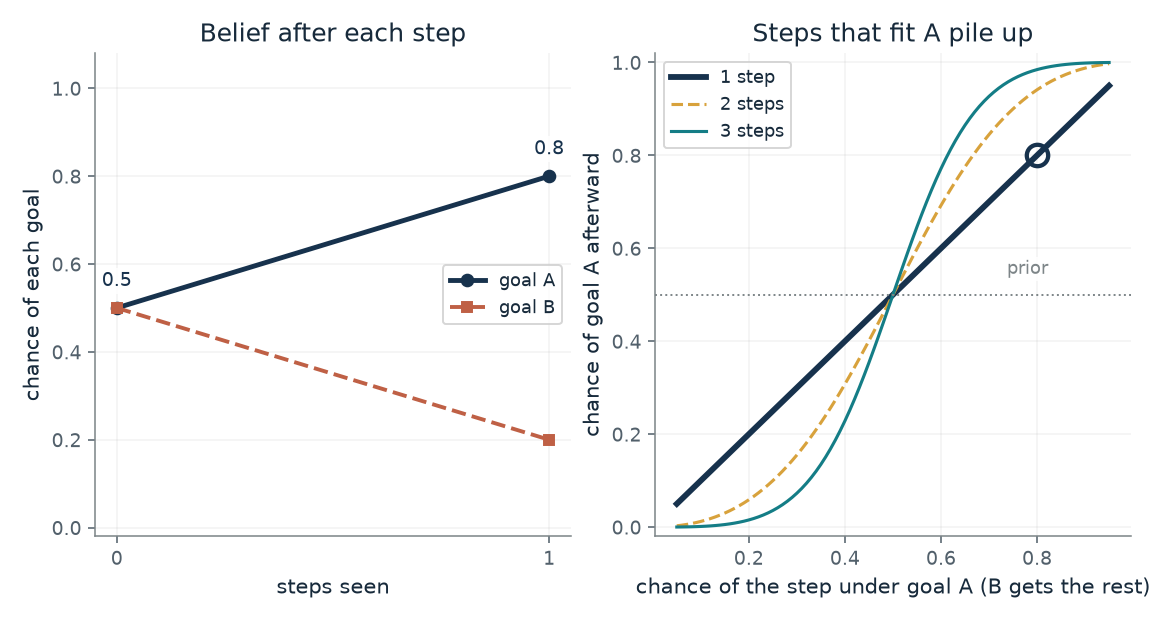

- **Goal A before any step:** 0.5
- **Goal A after the steps:** 0.8
- **Score of A (unscaled):** 0.4
- **Score of B (unscaled):** 0.1

Starting at 0.5 for goal A, 1 step with chance 0.8 under A and 0.2 under B give A a chance of 0.8. Each step multiplies A's score by 0.8 and B's by 0.2, so the pull compounds.

Score of A = 0.5 x 0.8^1 = 0.4. Score of B = 0.5 x 0.2^1 = 0.1. Chance of A = 0.4 / (0.4 + 0.1) = 0.8.

In [2]:
figure, values, explanation = goal_picture(**{'step_prob': 0.8, 'steps': 1, 'prior_a': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How do steps point to a goal?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Chance of the step under goal A = 0.8, Steps seen = 3, Prior chance of goal A = 0.5: One step at 0.8 against 0.2 gives A a chance of 0.8, the chapter's number. Three such steps multiply the odds of 4 to 1 three times, giving 64 to 1, so A reaches 0.985.

**Takeaway:** Each step multiplies the odds by how much likelier it is under one goal than the other, so a modest tilt compounds.

**Why it matters:** A machine that reads goals from steps is only as good as its picture of how a goal produces a step. The arithmetic is simple, so the assumptions carry the weight.

**In brains and behavior:** In the 2009 study, the ratings of 16 people tracked a richer model that lets goals change (correlation 0.97); the fixed-goal rule used in this demonstration, which is the simplest version, scored 0.82. Either is a fit to ratings, not a finding that people multiply probabilities.

**In machines:** A system that reads a user's goal from their actions can apply this rule exactly, if it is given a prior and an action model. Whether those are right is a separate check.

**Where it applies:** One goal for the whole walk, every step equally informative and independent given the goal, the prior and step chances known. The model of how a goal produces a step is an assumption; the circle study fitted people's ratings with richer planners.

**Check your understanding:** Prior for A is 0.2, step chance under A is 0.6 (0.4 under B), and two steps are seen. What is the chance of A?

<details><summary>Show the answer</summary>

Scores: A 0.2 x 0.36 = 0.072, B 0.8 x 0.16 = 0.128. The chance of A is 0.072 / 0.2 = 0.36, so the evidence has not overcome a low prior.

</details>

*Source: Chapter 22, Circles heading for a spot, and a model that let goals change. Book formula (inverse planning by Bayes' rule) and the chapter's small example of 0.8 and 0.2 with equal priors. The repeated steps with the same chance each time, and the other priors, are the companion's constructed extension. The chapter says the example is not a result from the circle study.*

## C22-D02: Is a skipped road a dislike or never known?

If two roads cost the same but one draws far fewer trips, does that show drivers dislike tolls?

Each route gets a cost, and its chance falls as the cost rises. At the default toll weight of 0.40 the two routes tie at 4.8, so drivers who know all three roads split evenly between them, with fewer on the costlier Back roads (at other toll weights the two do not tie: at 0.20 Express is cheapest at 4.2, and at 0.80 it costs 6.0, as much as Back roads). Drivers who never heard of Express choose between the other two. Mixing the groups leaves Express short. The analyst, who assumes full knowledge, finds the weights that reproduce these shares, and the shortfall appears as a toll weight that is too high.

$$
P(a\mid s,g)=\frac{e^{\beta Q_g(s,a)}}{\sum_{a'}e^{\beta Q_g(s,a')}},\qquad Q=-\text{cost},\ \beta=1
$$

**Symbols:** a: a route; Express, Arterial or Back roads; Q: the value of a route: minus its cost, where cost is 0.20 per minute plus the toll weight per dollar; beta: carefulness, taken as 1 here; zero would make every route equally likely; unaware share: the fraction of drivers who never heard of Express and choose only between the free roads

**Predict before looking:** Express and Arterial both cost 4.8. If 40 percent of drivers never heard of Express, predict whether an analyst who assumes full knowledge reads the toll as costing more or less than the true 0.40 per dollar.

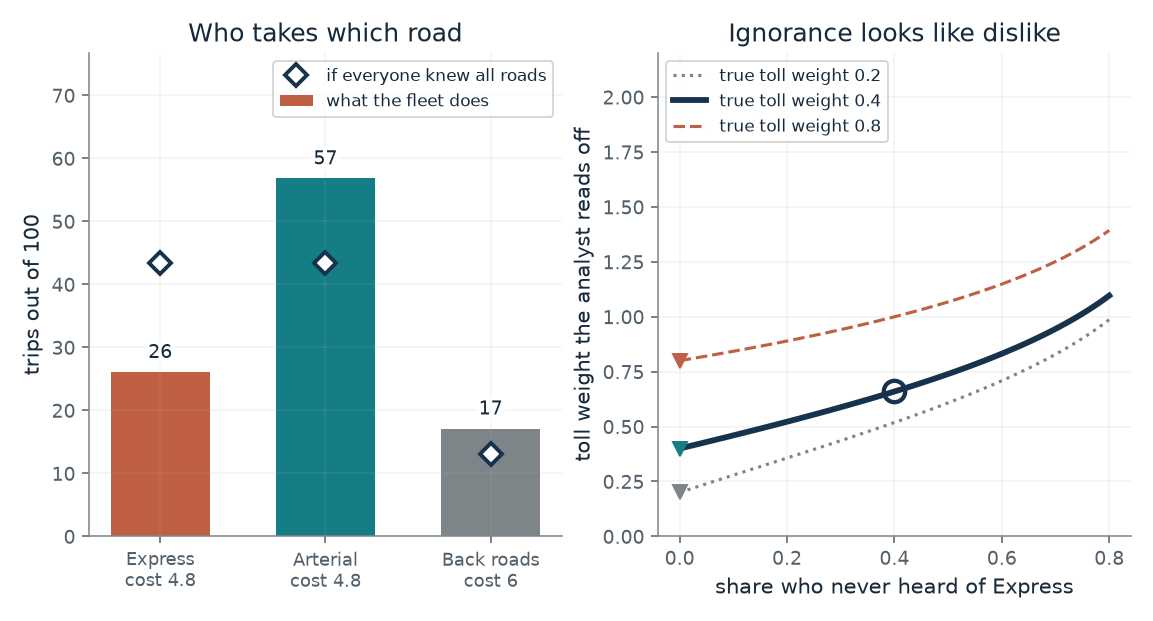

- **Express trips per 100:** 26.1
- **Toll weight the analyst reads:** 0.66
- **True toll weight:** 0.4
- **Hour of time, as the analyst values it ($):** 18.2

With 40 percent of drivers unaware of Express, it draws 26.1 trips per 100 against 43.5 if everyone knew it. The analyst reads a toll weight of 0.66 per dollar and an hour worth 18.2 dollars; the drivers' true toll weight is 0.4 and the true hour is worth 30 dollars.

Costs = 0.20 x minutes + 0.4 x toll: Express 4.8, Arterial 4.8, Back roads 6. Chance of a route = exp(-cost) / sum. Fleet share of Express = (1 - 0.4) x 0.435 = 0.261. Analyst: time weight = ln(share Arterial / share Back roads) / 6; toll weight = (6 x time weight - ln(share Express / share Arterial)) / 3.

In [3]:
figure, values, explanation = fleet_picture(**{'unaware': 0.4, 'toll_weight': 0.4})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Is a skipped road a dislike or never known?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of drivers who never heard of Express = 0.4, True toll weight per dollar = 0.4: The fleet puts 26.1 trips in 100 on Express and 56.8 on Arterial, though the two cost the same. The analyst reads a toll weight of 0.66 and an hour worth 18.2 dollars, not 30. Only the toll weight is distorted, because everyone knew both free roads.

**Takeaway:** A road that no one has been told about looks like a road everyone refuses. Ignorance and preference can produce the same trip counts.

**Why it matters:** An assistant that reads a person's detours as preferences would first need to ask which options that person knew were available. A system that logged which options each user was shown could do that; that is a proposal, not something the chapter tests.

**In brains and behavior:** The chapter's models of people reading each other use the same choice rule, with ratings of human observers on the other side. Nothing here measures how any person reasons about another.

**In machines:** The softmax is a modeling choice for noisy picking, written down exactly. It is a specification of the analyst's model, not a measurement of drivers.

**Where it applies:** All drivers share the same weights and carefulness, the unaware drivers have no other difference, and the analyst fixes carefulness at 1 and assumes everyone knew every road. Nothing here is data about real drivers.

**Check your understanding:** If nobody is unaware (unaware share 0), what toll weight does the analyst read, and what is an hour worth?

<details><summary>Show the answer</summary>

The analyst recovers the truth: 0.40 per dollar and an hour worth 60 x 0.20 / 0.40 = 30 dollars. The distortion comes from the unaware share, not from the method.

</details>

*Source: Chapter 22, A fleet that looked as if it disliked tolls. The chapter's invented fleet: Express 18 minutes with a 3 dollar toll, Arterial 24 minutes, Back roads 30 minutes, 0.20 per minute, 0.40 per dollar, 40 percent unaware. Its 26, 57 and 17 trips per 100, the 0.66 toll weight and the 18.2 dollar hour are reproduced at the default. Other unaware shares and toll weights are the companion's variations on the same invented model.*

## C22-D03: How unlikely is 21 right out of 24 by guessing?

Sarah picked the problem-solving photograph on 21 of 24 trials. How often would a guesser do that, and what does that rule out?

If each pick were an independent toss with chance p, the number right would follow the binomial pattern on the left. Adding up the chance of 21, 22, 23 and 24 right gives the tail. Raising p moves the whole pattern right, and a count that is surprising at 0.5 may be ordinary at 0.75.

$$
P(X\ge k)=\sum_{j=k}^{24}\binom{24}{j}\,p^{j}(1-p)^{24-j}
$$

**Symbols:** k: the number of trials answered right, out of 24; p: the assumed chance of a right pick on each trial if the picks were guesses; C(24, j): the number of ways to choose j right trials out of 24

**Predict before looking:** Before looking, guess whether 21 of 24 by pure guessing happens about once in a hundred, once in a thousand, or once in ten thousand attempts.

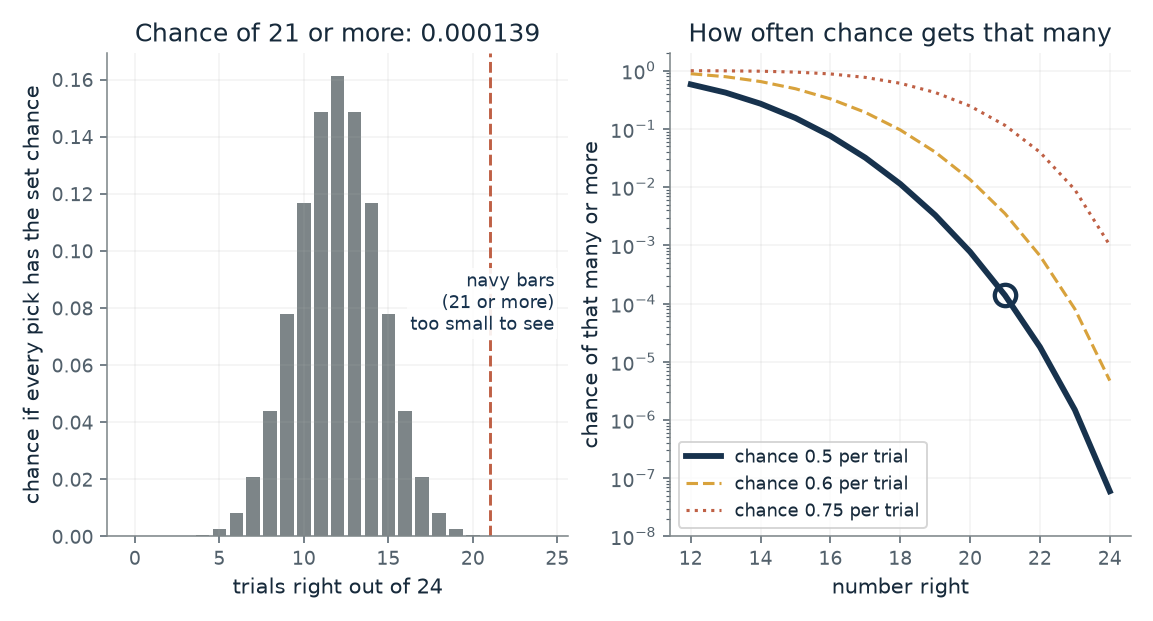

- **Expected right by chance:** 12
- **Chance of this many or more:** 0.000139
- **Rate right:** 0.875
- **Rate expected:** 0.5

If each of 24 picks had a 0.5 chance of being right, 21 or more right would have chance 0.000139. That is rare, so chance at that level fits poorly; it does not say which reading of the task explains the choices.

Chance of 21 or more = sum over j from 21 to 24 of C(24, j) x 0.5^j x 0.5^(24 - j) = 0.000139. Expected right = 24 x 0.5 = 12.

In [4]:
figure, values, explanation = sarah_picture(**{'correct': 21, 'chance': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How unlikely is 21 right out of 24 by guessing?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Trials right out of 24 = 21, Assumed chance of a right pick per trial = 0.5: At a chance of 0.5 per trial, 21 or more right has a chance of about 0.00014, roughly once in 7,200 attempts. At 0.75 per trial it would be 0.115, so a mildly informed guesser could reach it.

**Takeaway:** The count rules out a flat 50-50 guess. It leaves open every way a picker could do better than that.

**Why it matters:** Premack and Woodruff wrote that the experiment 'cannot itself decide among the alternative interpretations.' A tiny chance of guessing is not the same as support for any one reading.

**In brains and behavior:** The study was one chimpanzee. The count says nothing about what went on inside her.

**In machines:** The same count would apply to any system picking among two options, and would leave the same rival explanations open.

**Where it applies:** Trials are independent and share one chance p. The real task was not like that: Sarah missed three in a row on one problem, and every trial had a structure. The calculation says only how well a flat-chance model fits the count.

**Check your understanding:** At a chance of 0.5, how many right do you expect out of 24, and what is the exact chance of all 24?

<details><summary>Show the answer</summary>

The expected number is 24 x 0.5 = 12. All 24 right has chance 0.5 to the power 24, which is 5.96e-8.

</details>

*Source: Chapter 22, Understanding Another Mind (opening). Sarah's 21 of 24 and the 'about 12' by guessing are the chapter's, from Premack and Woodruff. The exact binomial tail is the companion's own calculation; the chapter does not print it. The rates 0.6 and 0.75 are constructed comparison levels.*

## C22-D04: How much does one pass tell you?

A tracker passes a standard false-belief story 95 times in 100 and a pattern-matcher 90. How far does one pass move belief that the test-taker tracks beliefs?

Bayes' rule with two types. Multiply the prior of each type by its chance of passing, then rescale. When both types pass nearly always, the two products stay close to the priors and the answer barely changes.

$$
P(\text{tracker}\mid\text{pass})=\frac{\pi\,q_T}{\pi\,q_T+(1-\pi)\,q_M}
$$

**Symbols:** pi: the chance of 'tracker' before the test (the prior); q_T: the tracker's chance of passing; 0.95 in the chapter's example; q_M: the pattern-matcher's chance of passing; 0.90 on the standard story, 0.30 on an altered story

**Predict before looking:** Starting at even odds, predict the chance of 'tracker' after a pass on the standard story, and then after a pass on an altered story that a pattern-matcher passes only 30 times in 100.

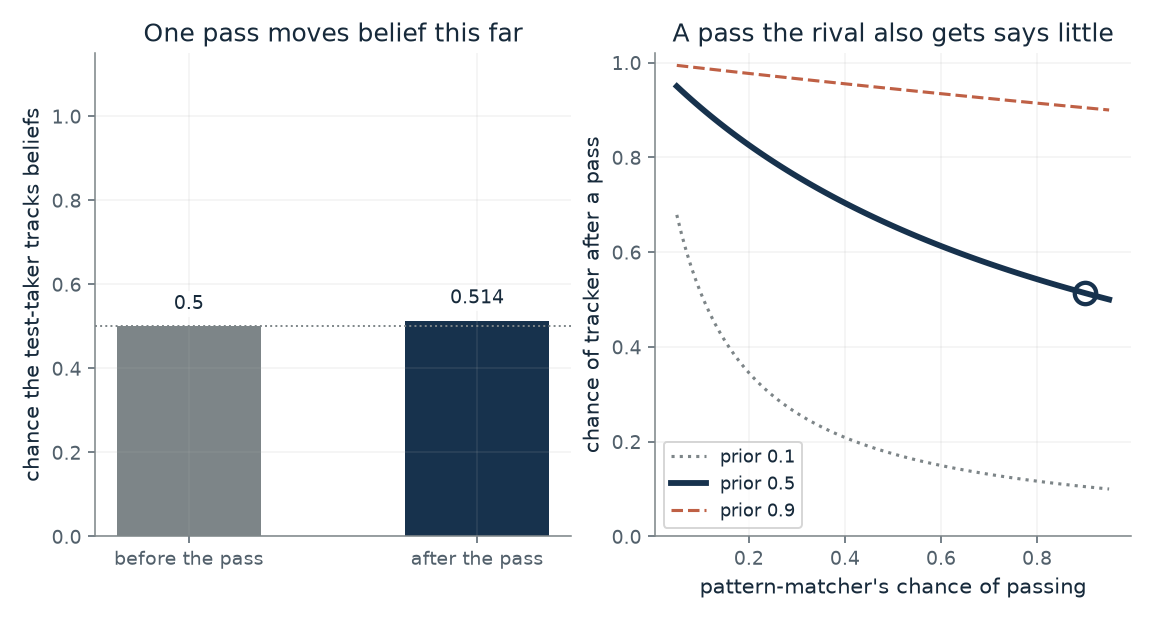

- **Chance of tracker before:** 0.5
- **Chance of tracker after one pass:** 0.514
- **Pass rate ratio, tracker over matcher:** 1.06
- **Tracker's pass rate:** 0.95

A tracker passes the story 95 times in 100 and a pattern-matcher 90. Starting at 0.5, one pass moves the chance of tracker to 0.514. The movement depends on the ratio 1.06, so a test the rival also passes teaches little.

Chance of tracker = 0.5 x 0.95 / (0.5 x 0.95 + 0.5 x 0.9) = 0.475 / 0.925 = 0.514.

In [5]:
figure, values, explanation = pass_picture(**{'matcher_pass': 0.9, 'prior': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much does one pass tell you?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Pattern-matcher's chance of passing = 0.3, Prior chance of tracker = 0.5: On the standard story, with the matcher at 0.90, one pass lifts the tracker from 0.5 to 0.51. Dropping the matcher to 0.30 on an altered story lifts it to 0.76. The same pass is worth more when the rival would likely have failed.

**Takeaway:** A pass is evidence only to the extent that the rival explanation would have failed. The ratio of pass rates sets how far belief moves.

**Why it matters:** This is the logic of an altered test version: change the story so that a script fails while real belief tracking does not. It is also why a perfect score on a standard test can say little about how a model or a person got there.

**In brains and behavior:** Children were tested with the Sally and Anne story; the chapter notes researchers disagree on why young children often fail when asked directly. No pass rate here is for children.

**In machines:** Strachan and colleagues tested language models with altered stories and found failures, but the changes also altered the physical setup, so failure does not show that the model lacks the ability.

**Where it applies:** Only two rival types, a known pass rate for each, and one test with independent passes. Real models and people are not two clean types, and the study found altered versions also changed the physical setup.

**Check your understanding:** The prior for 'tracker' is 0.1. The matcher passes 0.3 of the time. What is the chance of 'tracker' after one pass?

<details><summary>Show the answer</summary>

0.1 x 0.95 = 0.095 against 0.9 x 0.3 = 0.27, so 0.095 / 0.365 = 0.260. A low prior keeps the answer low even on a good test.

</details>

*Source: Chapter 22, Sarah's 21 of 24 and three rival readings. The chapter's constructed test-takers: a tracker at 0.95, a matcher at 0.90 on the standard story and 0.30 on the altered one, with even prior odds. The other pass rates and priors are the companion's variations. The chapter says the figures are suppositions; they are not measurements from Strachan and colleagues.*

## C22-D05: What do the printed correlations say?

A model correlates 0.97 with people's ratings in one study and 0.78 in another. How different are those, and what do they not show?

A correlation of 0 means the model's score tells you nothing about the rating. A correlation near 1 means they rise and fall together. Squaring it gives the share of variation that lines up, which makes the gap between 0.82 and 0.97 (0.67 against 0.94) easier to feel than the gap between 0.97 and 0.96.

$$
r^{2}=\text{the share of variation in ratings that lines up with the model}
$$

**Symbols:** r: the correlation between a model's predictions and people's average ratings, from -1 to 1; r squared: the correlation squared; the share of variation in the ratings that a straight-line fit to the model's scores accounts for

**Predict before looking:** Pick the 'knows everything' model for beliefs. What do you expect its cloud to look like, and why might a model that is blind to false belief have no correlation with beliefs at all?

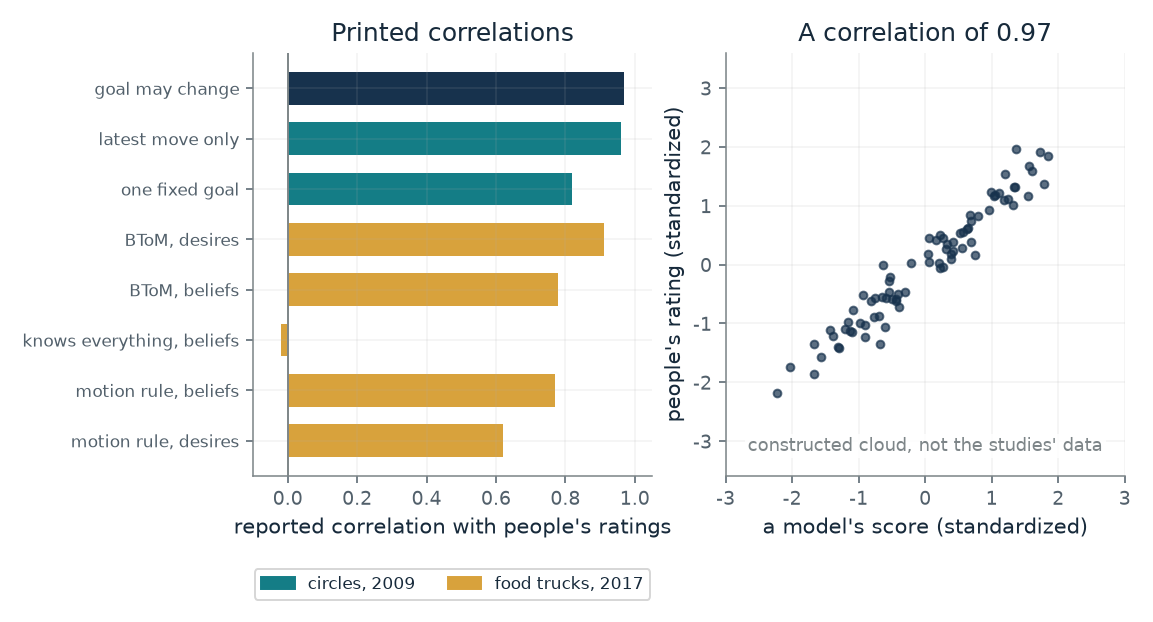

- **Correlation:** 0.97
- **Share of variation shared (r squared):** 0.941
- **Basis:** held-out ratings of 16 people, same experiment

Baker, Saxe and Tenenbaum 2009, circles: goal may change correlated 0.97 with people's ratings, held-out ratings of 16 people, same experiment. A correlation is a fit to behavior, and a squared correlation of 0.941 means that share of the variation in ratings lines up with the model's.

r = 0.97, so r squared = 0.97 x 0.97 = 0.941. The cloud on the right is a seeded construction with this exact sample correlation.

In [6]:
figure, values, explanation = reported_picture(**{'model': '2009: goal may change'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What do the printed correlations say?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Model and study = 2017: knows everything, beliefs: A model that assumes the student knew everything scored minus 0.02 for beliefs: no line-up at all. It could not see the student's mistaken belief, so it had nothing to say about it.

**Takeaway:** The closer the correlation to 1, the tighter the cloud, but even 0.78 leaves much unshared and 0.97 is still a fit to ratings, not a mechanism.

**Why it matters:** Two cautions from the chapter apply: a motion rule with fitted weights matched the belief model on beliefs (0.77 against 0.78) while doing worse on desires, and the authors call their claim a computational-level claim, which says what is computed, not that observers run this procedure.

**In brains and behavior:** The ratings are those of human observers watching circles and a student; the correlation measures agreement with their average, not how they reason.

**In machines:** The models are Bayesian planners fitted to ratings and solved approximately. They are not deployed assistants.

**Where it applies:** The 2009 values are cross-validated on held-out ratings from the same experiment, and the 2017 values are correlations across scenarios of observers' average ratings, not separate scores per observer. The two sets are not directly comparable.

**Check your understanding:** How much more of the variation in ratings does the 0.97 model line up with than the 0.82 model?

<details><summary>Show the answer</summary>

0.97 squared is 0.941 and 0.82 squared is 0.672, a difference of 0.269, about 27 percentage points.

</details>

*Source: Chapter 22, A student looks at the far spot and turns back. The correlations are the chapter's printed values: 0.97, 0.96 and 0.82 for the 2009 circle models (held-out ratings of 16 people), and 0.91 for desires and 0.78 for beliefs with BToM, minus 0.02 for a model that assumes everything is known, and 0.77 and 0.62 for a motion rule (across 73 scenarios). The scatter plot is a constructed cloud and not either study's data. The chapter does not print r squared; it is the companion's arithmetic.*

## C22-D06: How many pairs does a ranking give, and how noisy is a choice?

A rater ranks several outputs. How many pairs of preferences does that produce, and what reward gap would make two raters agree about as often as the labelers in the study did?

A ranking of K outputs orders every pair, so it gives K(K-1)/2 comparisons, with ties omitted. If raters choose with a logistic rule on a reward gap, a larger gap makes them pick the better answer more often and agree with one another more often. Reading the study's agreement figure through this rule gives one summary gap, under strong assumptions.

$$
\binom{K}{2}=\frac{K(K-1)}{2},\qquad P(\text{better})=\frac{1}{1+e^{-\Delta}},\qquad P(\text{agree})=p^{2}+(1-p)^{2}
$$

**Symbols:** K: the number of outputs a rater ranks, from 4 to 9 in the study; Delta: the reward gap between two answers in some units; a modeling assumption; p: the chance a rater picks the higher-reward answer; a logistic rule, the two-option case of the fleet's softmax with carefulness 1

**Predict before looking:** Nine outputs ranked: predict the number of pairs before moving the slider. Then predict the gap at which two raters would agree about 73 percent of the time.

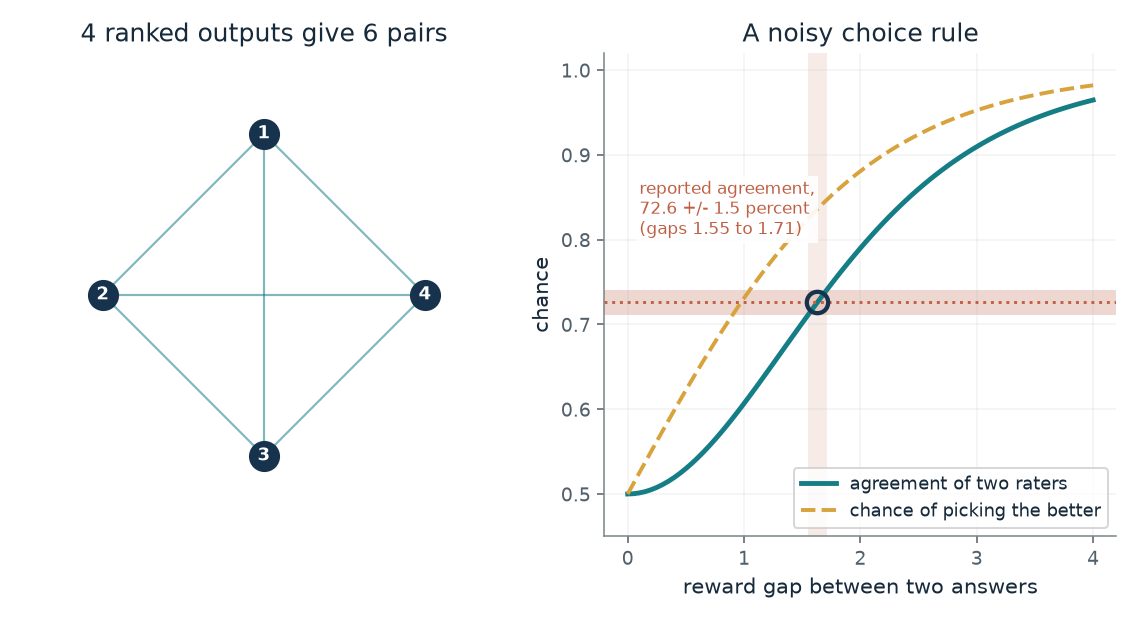

- **Pairs from the ranking:** 6
- **Chance of picking the better answer:** 0.836
- **Two raters agree:** 0.726
- **Reward gap (72.6 +/- 1.5 percent implies 1.55 to 1.71):** 1.63

A ranking of 4 outputs yields 6 pairs of preferences, ties aside. At a reward gap of 1.63 a rater picks the better answer with chance 0.836, and two such raters agree with chance 0.726. The paper's 72.6 +/- 1.5 percent maps to gaps of about 1.55 to 1.71 under this made-up rule; 1.63 is one illustrative value.

Pairs = 4 x (4 - 1) / 2 = 6. Chance of the better = 1/(1 + e^-1.63) = 0.836. Agreement = 0.836^2 + 0.164^2 = 0.726.

In [7]:
figure, values, explanation = ranking_picture(**{'outputs': 4, 'gap': 1.63})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many pairs does a ranking give, and how noisy is a choice?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Outputs ranked (K) = 9, Reward gap between two answers = 1.63: Nine outputs give 36 pairs. A gap of 1.63 makes a rater pick the better answer with chance 0.836 and two raters agree with chance 0.726, the reported 72.6 percent under these assumptions. But the paper reports 72.6 +/- 1.5 percent, which under the same rule means gaps from about 1.55 to 1.71 (the shaded band), so 1.63 is one illustrative value.

**Takeaway:** A short ranking becomes many pairs. Under this simple rule, agreement of 72.6 percent would mean each rater picks the higher-reward answer about 84 percent of the time, so a good deal of label noise remains.

**Why it matters:** A learned reward is a stand-in for what raters preferred, estimated from noisy choices. The authors note that labelers cannot see the context in which an answer will be used.

**In brains and behavior:** The raters are about 40 contractors. Nothing here measures how any person weighs outputs.

**In machines:** The reward model is trained on the pairs from each ranking; the logistic rule is a standard way to model that, written here as the companion's own specification, not a quote from the paper.

**Where it applies:** Every rater chooses independently by the same logistic rule and sees the same gap on every pair, and one gap applies to every pair. The paper reports none of these. Real raters differ and real gaps vary, so the single gap is a summary under these assumptions and not something the study estimated; different mixtures of easy and hard pairs could give the same 72.6 percent.

**Check your understanding:** At a gap of 0, what is the chance a rater picks the better answer, and what is the agreement between two raters?

<details><summary>Show the answer</summary>

With no gap the choice is a coin flip, 0.5, and two raters agree with chance 0.5 squared plus 0.5 squared, which is 0.5.

</details>

*Source: Chapter 22, What InstructGPT inferred from rankings. The pair counts (4 outputs give 6 pairs, 9 give 36) and the 72.6 percent labeler agreement are the chapter's. The logistic choice rule and the reward gap that reproduces 72.6 percent (about 1.63) are the companion's own illustration: the chapter says only that the reward model treats the higher-scoring answer as likelier to be preferred. The source figure is 72.6 +/- 1.5 percent (the chapter's footnote on Ouyang and colleagues), which under the same rule corresponds to gaps from about 1.55 to 1.71; 1.63 is a single illustrative value, not the book's number or the paper's.*

## Bring it to your own question

Ask what the observed agent could see or know, what options it had, and what a choice rule with some noise would predict. Then score the candidate goals with Bayes' rule, using the chance of each step under each goal. Before reading a choice as a preference, compare the readings that fit with and without missing knowledge. When a test result is offered as proof of understanding, compare how likely a pass is under each rival explanation, and say that a good fit to behavior does not establish a private motive or belief.

Use the `mmi-ch22-another-mind` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.